# Layered-earth calibration and interval coverage

**Question:** How do regularization and a frozen frequency holdout affect resistivity recovery on a seeded three-layer MT model?

**Level 2 — Applied analysis**  
**Prerequisites:** Level 1 and arrays/logarithms; 35 min.



## Objectives

Question: How do frequency holdout and regularization change conditional layer estimates and bootstrap coverage in the fixed-thickness MT model?



## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.



## Data

This lesson uses a seeded three-layer synthetic calibration with fixed 250 m and 600 m layer thicknesses, 24 frequencies and 48 bootstrap realizations. Six frequencies are withheld before fitting. The measured Clear Lake cl061 EDI appears only as a separately screened QC record and contributes no values to these synthetic inversions.


**Source and rights:** Clear Lake station cl061 EDI, USGS/EarthScope [station product](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061), raw object [USGS-GMEG.2022.cl061.edi](https://data.earthscope.org/archive/seismology/products/emtf/surveys/2022/MT_TF_USGS-GMEG.2022.cl061/USGS-GMEG.2022.cl061.edi), and [USGS Clear Lake release](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california). The source release is marked CC0; the EDI requests citation. This repository uses the attributed QC derivative only and does not redistribute another raw EDI copy. cl061 remains QC-only because its 1D eligibility gate fails.

## Method

This artifact is explicitly synthetic: a 1D two-layer earth, `[180,20] Ω·m`, upper thickness 450 m, 24 frequencies, 48 independent noisy realizations and 128 bootstrap draws per realization. Empirical interval coverage is `C=N⁻¹Σ1[ρtrue∈CI]`; the independent unit is the realization, not each bootstrap draw. Compare coverage with the 95% nominal level and stored Wilson bounds, then inspect interval width in Ω·m. The interval is conditional on fixed thickness, independent Gaussian real/imaginary errors, bounds and regularization. It is not a field confidence guarantee; high apparent coverage can coexist with biased or weakly resolved layers.

Parameters are log-resistivities: positive by construction, with equal steps representing equal multiplicative changes. Complex residuals use per-real-component sigma; real and imaginary parts both inform the fit. Frequencies are not independent depth samples: sensitivity kernels overlap, so one period does not identify one interface. Local sensitivity and coverage remain conditional on the fixed parameterization and cannot rule out global equivalence.



Create the seeded inputs before evaluating the forward, objective and sensitivity methods. The frequency mask and error model are fixed before any fit.

In [1]:
# Generate the seeded observations and frozen frequency mask used by each method below.
import sys
from pathlib import Path
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em

f = np.logspace(-2, 2, 24)
h = np.array([250.0, 600.0])
truth = np.array([80.0, 8.0, 350.0])
z0 = em.impedance(truth, h, f)
sigma = np.maximum(np.abs(z0) * 0.035, 1e-12)
rng = np.random.default_rng(20261027)
zobs = z0 + sigma * (rng.normal(size=len(f)) + 1j * rng.normal(size=len(f)))
active = np.arange(len(f)) % 4 != 0
print("active:", int(active.sum()), "held out:", int((~active).sum()))


active: 18 held out: 6


Recompute the layered-earth complex forward response.

In [2]:
# Run the product layered-earth forward method.
z_target = em.impedance(truth, h, f)
print("periods:", len(z_target), "finite:", bool(np.isfinite(z_target).all()))


periods: 24 finite: True


Convert complex impedance into apparent resistivity and phase.

In [3]:
# Convert the modeled response to the observables used by interpretation.
target_curves = em.curves(z_target, f)
print("median apparent resistivity Ω·m:", float(np.median(target_curves["apparent"])))


median apparent resistivity Ω·m: 37.915292342294244


Evaluate the declared weighted complex objective.

In [4]:
# Evaluate the exact residual objective at the declared model.
objective = em.objective_residual(np.log(truth), h, f, zobs, sigma, 0.001, active)
print("objective length:", len(objective), "norm:", float(np.linalg.norm(objective)))


objective length: 38 norm: 0.9236433391734254


Inspect local sensitivity conditional on fixed thickness.

In [5]:
# Compute the data-only local identifiability diagnostic.
local_rank = em.identifiability(truth, h, f, sigma, active)
print("effective rank:", local_rank["effective_rank"], "/", local_rank["parameter_count"])


effective rank: 3 / 3


Confirm the runtime versions and calibration receipt before plotting the realization-level results. This records the computational environment and checks that the comparison refers to the declared 48 fits rather than an unrelated artifact.

In [6]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib", "scipy"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Inspect synthetic calibration provenance and independent realization rows.
import json
from pathlib import Path

cal = json.loads((root / "data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
print(
    cal["kind"],
    cal["calibration_model"],
    "Ω·m; thickness",
    cal["fixed_thickness_m"],
    "m; frequencies",
    len(cal["frequencies_hz"]),
)
print(
    "realizations",
    cal["realizations"],
    "bootstrap each",
    cal["bootstrap_samples_per_realization"],
    "nominal",
    cal["confidence"],
    "coverage",
    cal["coverage_per_layer"],
)


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
independent_seeded_conditional_bootstrap_coverage [180.0, 20.0] Ω·m; thickness [450.0] m; frequencies 24
realizations 48 bootstrap each 128 nominal 0.95 coverage [0.875, 1.0]


### Diagnostic 2

This diagnostic recomputes realization-level interval coverage and median width from the declared calibration fits. Comparing empirical coverage with the nominal 90% target shows how often conditional intervals contain each known synthetic layer; interval width records precision separately. These quantities answer different questions, so neither is interpreted as geological validation.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Recompute coverage and median interval widths from the 48 recorded fits.
import matplotlib.pyplot as plt

rows = cal["rows"]
truth = np.asarray(cal["calibration_model"], float)
cover = np.asarray([r["covered"] for r in rows], bool)
ci = np.asarray([r["interval_ohm_m"] for r in rows], float)
cov = cover.mean(0)
width = np.median(ci[:, 1, :] - ci[:, 0, :], axis=0)
print("coverage", cov, "; median interval width Ω·m", width)


coverage [0.875 1.   ] ; median interval width Ω·m [44.96804628  1.67527305]


### Plot realization-level coverage

The quantities above are recomputed from all 48 recorded fits, not taken from the visualization. These panels compare empirical coverage with the requested confidence and show conditional interval width for the upper and lower layers.

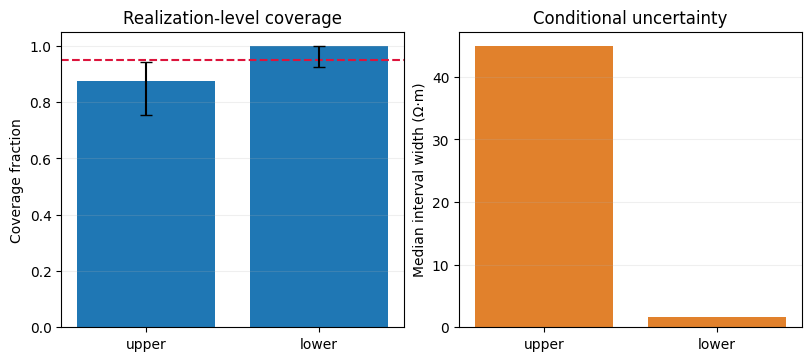

In [8]:
# Plot realization-level coverage.
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, cov)
ax[0].axhline(cal["confidence"], ls="--", color="crimson")
ax[0].errorbar(
    x,
    cov,
    yerr=[
        np.maximum(0, cov - np.asarray(cal["coverage_wilson95_lower"])),
        np.maximum(0, np.asarray(cal["coverage_wilson95_upper"]) - cov),
    ],
    fmt="none",
    capsize=4,
    color="black",
)
ax[0].set(
    xticks=x,
    xticklabels=["upper", "lower"],
    ylim=(0, 1.05),
    ylabel="Coverage fraction",
    title="Realization-level coverage",
)
ax[1].bar(x, width, color="#e1812c")
ax[1].set(
    xticks=x, xticklabels=["upper", "lower"], ylabel="Median interval width (Ω·m)", title="Conditional uncertainty"
)
[a.grid(axis="y", alpha=0.2) for a in ax]
plt.show()


### Controlled regularization experiment

This is a reproducible **synthetic** 1D sounding, not a field interpretation. Generate a three-layer response with the repository forward operator, add seeded complex noise and fit only active periods. Every fourth frequency is withheld before fitting and used only for the reported validation residual. Thickness is fixed, so this experiment cannot test interface-depth recovery. A beta sweep exposes the fit/regularization trade-off under identical data, seed, start model and solver budget.

Synthetic truth: resistivity in ohm m, thickness in m and frequency in Hz. Holdout data are never passed to the solver. Local identifiability is conditional and is not a uniqueness proof.

In [9]:
# Generate one seeded MT sounding and solve three regularization strengths.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em
import numpy as np

f = np.logspace(-2, 2, 24)
h = np.array([250.0, 600.0])
truth = np.array([80.0, 8.0, 350.0])
z0 = em.impedance(truth, h, f)
rng = np.random.default_rng(20261027)
sigma = np.maximum(abs(z0) * 0.035, 1e-12)
zobs = z0 + sigma * (rng.normal(size=len(f)) + 1j * rng.normal(size=len(f)))
active = np.arange(len(f)) % 4 != 0
betas = [0.0, 0.001, 0.1]
fits = {}


### Solve the regularized inverse problems

The synthetic impedance, uncertainty, and withheld-frequency mask are fixed above. This step calls the product Levenberg–Marquardt implementation at three beta values and reports active and held-out component WRMS separately.

In [10]:
# Solve the regularized inverse problems.
for beta in betas:
    result = em.invert_mt(
        h,
        f,
        zobs,
        sigma,
        active=active,
        initial=[100.0, 30.0, 150.0],
        beta=beta,
        methods=("mt-lm",),
        max_nfev=120,
        record_every=20,
    )["mt-lm"]
    fits[beta] = result
    metrics = result["metrics"]
    print(
        f"beta={beta:g}; model={np.round(result['model'], 2)} Ω·m; "
        f"fit WRMS={metrics['active_component_wrms']:.3f}; "
        f"held-out WRMS={metrics['withheld_component_wrms']:.3f}"
    )


beta=0; model=[ 77.05   7.9  326.58] Ω·m; fit WRMS=0.855; held-out WRMS=1.010
beta=0.001; model=[ 77.03   7.9  326.49] Ω·m; fit WRMS=0.855; held-out WRMS=1.011
beta=0.1; model=[ 74.87   7.97 318.04] Ω·m; fit WRMS=0.861; held-out WRMS=1.029


### Compare fit and held-out responses across beta

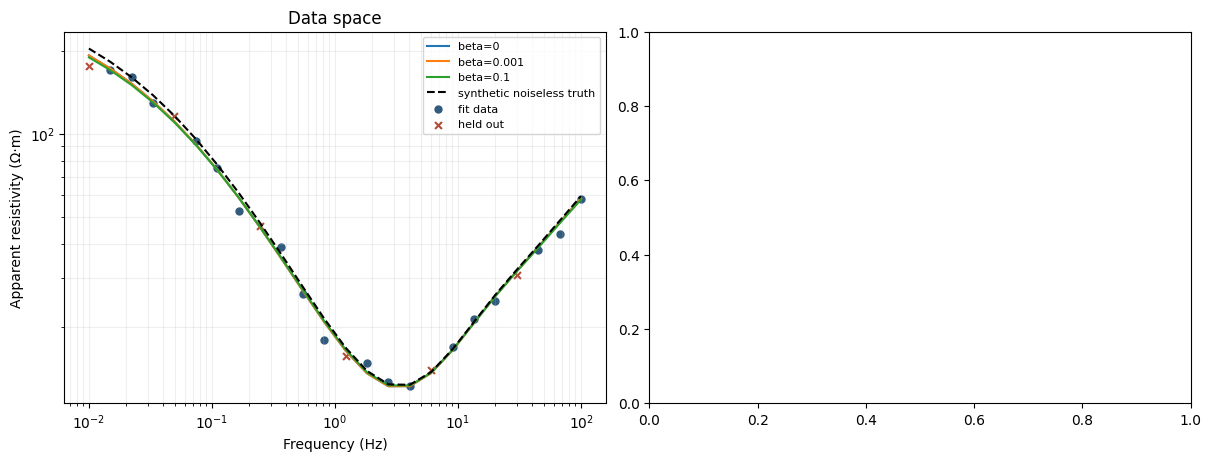

In [11]:
# Compare solved data-space predictions and fixed-thickness layer models.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for beta, result in fits.items():
    ax[0].loglog(f, result["predicted"]["apparent"], label=f"beta={beta:g}")
truth_apparent = abs(z0) ** 2 / (em.MU * 2 * np.pi * f)
ax[0].loglog(f, truth_apparent, "k--", label="synthetic noiseless truth")
for mask, marker, color, label in (
    (active, "o", "#315b7d", "fit data"),
    (~active, "x", "#b34a36", "held out"),
):
    observed_apparent = abs(zobs[mask]) ** 2 / (em.MU * 2 * np.pi * f[mask])
    ax[0].scatter(f[mask], observed_apparent, s=25, marker=marker, color=color, label=label)
ax[0].set(xlabel="Frequency (Hz)", ylabel="Apparent resistivity (Ω·m)", title="Data space")
ax[0].grid(True, which="both", alpha=0.2)
ax[0].legend(fontsize=8)
plt.show()


### Compare recovered layer models

The first panel compares predicted apparent resistivity with noisy fit and withheld observations. This panel shows the three solver outputs against the known synthetic model while layer thickness remains fixed, so resistivity trade-offs are visible. The curves test this frequency band and fixed geometry only; they do not demonstrate recovery of interface depths or uniqueness.


In [12]:
# Compare recovered layer models.
layer_ids = np.arange(3)
bar_width = 0.24
for position, beta in enumerate(betas):
    offset = (position - 1) * bar_width
    ax[1].bar(layer_ids + offset, fits[beta]["model"], bar_width, label=f"beta={beta:g}")
ax[1].scatter(layer_ids, truth, marker="D", color="black", label="synthetic truth", zorder=3)
ax[1].set(
    xticks=layer_ids,
    xticklabels=["Layer 1", "Layer 2", "Layer 3"],
    ylabel="Resistivity (Ω·m)",
    title="Model space; thickness fixed",
)
ax[1].grid(axis="y", alpha=0.2)
ax[1].legend(fontsize=8)
fig.suptitle("MT regularization · synthetic 1D · bounded CPU least squares")
plt.show()


Compare active and withheld frequencies separately, then inspect how beta changes the fixed-thickness model. These are controlled synthetic outputs; the withheld rows assess prediction within the same generator and do not prove geological uniqueness.

The synthetic MT forward recurrence uses complex impedance through finite layers. For positive resistivity, fitting in log space prevents nonphysical negative values. The experiment reserves frequencies before constructing the optimization mask; every optimizer sees the same active observations, initial model, fixed thicknesses, bounds and uncertainty. Compare the resulting active and held-out normalized residuals, not just apparent-resistivity curves. The beta sweep changes regularization strength and can trade fit for smoothness. A withheld residual that worsens while training improves is evidence of a predictive trade-off. Since thickness is held fixed, the layer interfaces are imposed assumptions, not recovered parameters.

## Results

Across 48 seeded fits, the 95% interval coverage is 0.875 for the upper layer and 1.000 for the lower; median widths are 44.97 and 1.675 Ω·m. Increasing beta from 0 to 0.1 changes the third-layer estimate from 326.58 to 318.04 Ω·m and held-out WRMS from 1.010 to 1.029.
### Bootstrap calibration contract

All 48 realizations use a fixed 450 m thickness and the same synthetic model, so the displayed coverage is conditional on those choices.

**Answer:** Across 48 seeded fits, the 95% interval coverage is 0.875 for the upper layer and 1.000 for the lower; median widths are 44.97 and 1.675 Ω·m. Increasing beta from 0 to 0.1 changes the third-layer estimate from 326.58 to 318.04 Ω·m and held-out WRMS from 1.010 to 1.029.


## Summary

The lower layer meets the nominal coverage in this calibration while the upper layer misses it, and wider regularization modestly worsens held-out WRMS. Fixed thickness, one synthetic family and 48 realizations limit these results to conditional calibration, not field uncertainty.



## References

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)

EarthScope cl061 product record: https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061. The USGS dataset DOI, citation and CC0 derivative-only decision are stated in Data above.